Прв фајл од проектна задача -  истражување на GCN (Graph Convolution Network)
===

Почитувани, во овој фајл го тестираме Graph Convolution Network кој подоцна ќе го споредиме со GraphSAGE и GAT. Овие 3 невронски мрежи се специјализирани за графови односно учат од две работи: од јазлите и од рабовите.

Нашето податочно множество е неориентиран и нетежински граф кој се занимава со протеини. Ни дава два типа на информации: карактеристики на протеинот и конекцијата на протеинот со другите протеини. Секој од протеините припаѓа на еден од 58-те видиви па 58-те карактеристики не се 58 различни својства на протеинот, тие се користат за да се означи на кој од 58-те биолошки видови припаѓа протеинот. На пример: [0, 0, 1, 0, 0 ... 0]. Вредноста 1 означува дека протеинот припаѓа на третиот вид, а 0 дека не припаѓа на останатите видови.

Исто така ребрата на графот даваат многу важна информација: биолошки асоцијации помеѓу протеините. Целта на ова податочно множество е предвидување на нови асоцијации помеѓу протеините - link prediction. Моделот учи од познатите асоцијации во множеството за тренирање, а потоа предвидува кои парови протеини би можеле да бидат поврзани. За евалуација се проверува колку добро моделот ги рангира вистинските асоцијации над негативните примери кои се создаваат random.





In [1]:
!pip install torch-geometric --quiet

!pip install pyg-lib torch-scatter torch-sparse \
    -f https://data.pyg.org/whl/torch-2.11.0+cu130.html --quiet

!pip install ogb --upgrade --quiet



> pip install torch torch_geometric --quiet


Првата линија го инсталира PyTorch (torch) кој се користи за креирање и тренирање на невронски мрежи. Исто така го инсталира и PyTorch Geometric (torch_geometric) кои овозможува работа со графови и GCN модели. „quiet“ значи да се прикажуваат помалку пораќи за време на инсталација



> !pip install pyg-lib torch-scatter torch-sparse \
    -f https://data.pyg.org/whl/torch-2.11.0+cu130.html --quiet


Втората линија инсталира дополнителни библиотеки потребни за PyTorch Geometric, како torch-scatter, torch-sparse и pyg-lib. Со -f се кажува од каде да ги преземе соодветните верзии, quiet повторно ги намалува пораките при инсталација.



> !pip install ogb --upgrade --quiet

третата линија ја инсталира библиотеката Open Graph Benchmark, која ги обезбедува графичките податочни множества што ги користиме, како ogbl-ppa. --upgrade значи да се инсталира најнова достапна верзија.



In [2]:
!pip show torch

Name: torch
Version: 2.11.0+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, ogb, peft, sentence-transformers, timm, torchdata, torchvision


In [3]:
from ogb.linkproppred import PygLinkPropPredDataset
from torch_geometric.loader import DataLoader

import torch
from torch_geometric.data.data import DataEdgeAttr, DataTensorAttr
from torch_geometric.data.storage import GlobalStorage

/usr/local/lib/python3.13/dist-packages/outdated/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


PygLinkPropPredDataset ни овозможува да го вчитаме OGB податочното множество за link prediction, во нашиот случај ogbl-ppa.

DataLoader -  ги организира податоците во batches за време на тренирањето.

torch - PyTorch библиотека која се користи за работа со тензори, невронски мрежи и тренирање на моделот.

DataEdgeAttr, DataTensorAttr, GlobalStorage --> класи од PyTorch Geometric кои ќе ги видиме подоцна

In [4]:
torch.serialization.add_safe_globals(
    [DataEdgeAttr, DataTensorAttr, GlobalStorage]
)

Оваа линија му кажува на PyTorch: Овие три класи се безбедни и дозволи ги кога вчитуваш зачувани PyG податоци. Затоа што ogbl-ppa е PyG податочно множество.

In [5]:
dataset = PygLinkPropPredDataset(name = "ogbl-ppa")

Downloaded 0.38 GB: 100%|██████████| 388/388 [00:24<00:00, 15.85it/s]


Extracting dataset/ppassoc.zip


Processing...


Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00,  2.40it/s]


Converting graphs into PyG objects...


100%|██████████| 1/1 [00:00<00:00, 309.04it/s]


Saving...


Done!


Со ова се вчитува ogbl-ppa dataset-от преку PygLinkPropPredDataset и се зачувува во променливата dataset.

PPA - Protein protein association

Ние имаме само dataset[0] затоа што ogbl-ppa е направен како едно големо податочно множество што содржи еден граф, а не многу одделни графови.

In [6]:
dataset[0]

Data(num_nodes=576289, edge_index=[2, 42463862], x=[576289, 58])

In [7]:
len(dataset)

1

In [8]:
print(dataset[0].x.shape)
print(dataset[0].edge_index.shape)

torch.Size([576289, 58])
torch.Size([2, 42463862])


Со функцијата len(dataset) можеме да го потврдиме претходно кажаното - дека нашето податочно множество има само еден граф. Исто така можеме да забележиме дека имаме 2 типа на податоци:


> Data(num_nodes=576289, edge_index=[2, 42463862], x=[576289, 58])

Имаме вкупно 576 289 протеини, за секој од нив имаме 58 карактеристики кои ни кажуваат во кој од 58-те видиви спаѓа протеинот (како што објаснивме погоре). Тие податоци ги чуваме во променливата „dataset[0].x“. Исто така имаме и dataset[0].edge_index во кој го чуваме секој пар протеини што се поврзани на некаков биолошки начин. За тоа повеќе детали ќе објасниме подоцна. Сега засега само треба да знаеме дека ни требаат и двата типа на податоци за да предвидиме кои протеини се поврзани меѓу себе.


In [9]:
torch.isnan(dataset[0].x).sum()

tensor(0)

In [10]:
print("Is there any nan values in x")
print(torch.isnan(dataset[0].x).sum())
print("Is there any nan values in edge_index")
print(torch.isnan(dataset[0].edge_index).sum())

Is there any nan values in x
tensor(0)
Is there any nan values in edge_index
tensor(0)


In [11]:
print(dataset[0].edge_index.min())
print(dataset[0].edge_index.max())
print("num_nodes:", dataset[0].num_nodes)

tensor(0)
tensor(576288)
num_nodes: 576289


Во претходните полиња проверуваме валидност да податоците во податочното множество. Односно дали има празни вредности и во двата типа на податоци како и дали вредностите што се наоѓаат во edge_index соодветствуваат со индексите на протеините или бегаат од опсегот.

In [12]:
import torch

if not hasattr(torch, "_real_load"):
    torch._real_load = torch.load

def trusted_load(*args, **kwargs):
    kwargs["weights_only"] = False
    return torch._real_load(*args, **kwargs)

torch.load = trusted_load



> if not hasattr(torch, "_real_load"):
    torch._real_load = torch.load

Проверува дали torch веќе има атрибут _real_load. Ако нема ја зачувува оригиналната функција torch.load под тоа име.

Објаснување на функцијата „trusted_load“:
*args и **kwargs --> прифати ги буквално било кои аргументи кој ќе дојдат од torch.load



> kwargs["weights_only"] = False
    return torch._real_load(*args, **kwargs)

 Овие две линии значат, не ги земај само тежините туку земи го целиот објект. И на крајот користи го оригиналниот loader кој го зачувавме претходно.

 Последната линија значи дека од сега понатаму кога нашиот код направи torch.load(...), ние всушност правиме trusted_load(...)






In [13]:
split_edge = dataset.get_edge_split()
graph = dataset[0]
graph.x = graph.x.float()
print(graph.x.dtype)

torch.float32


get_edge_split() е готова функција од PygLinkPropPredDataset, таа ги зема
ребрата и ги дели на ребра за тренирање, валидација и тестирање.

Од друга страна во променливата graph ги чуваме и јазлите и ребрата. Односно и 58-те карактеристики на протеините и секој пар протеини кој имаат било каква биолошка конекција меѓу нив.

Доколку забележуваме внимателно, ќе видиме дека во последниот и претпоследниот ред внимаваме карактеристиките на графот да бидат децимални броеви наместо цели. (Пр. 1.0 наместо 1). Тоа ни е потребно затоа што во процесот на тренирање ни требаат исклучително децимални карактеристики.

In [14]:
train_edge, valid_edge, test_edge = split_edge["train"], split_edge["valid"], split_edge["test"]

split_edge е речник и во него имаме 3 главни клучеви: train, valid и test.
Секој од овие клучеви го запишуваме во посебна променлива како што е направено погоре.

In [15]:
valid_edge

{'edge': tensor([[145770, 110372],
         [426863, 530655],
         [361865, 420758],
         ...,
         [399989, 405159],
         [232672, 423416],
         [482297, 387720]]),
 'edge_neg': tensor([[500507, 173386],
         [336022, 229224],
         [435382, 429875],
         ...,
         [475514, 193934],
         [442108, 180966],
         [169069, 302110]])}

Со командата погоре можеме да видиме дека во податочното множество имаме и позитивни и негативни ребра. Позитивни ребра се ребрата што навистина постојат меѓу протеините (конекциите меѓу протеините што се реални). Негативните ребра се рандом направени, тие не постојат во реалноста. Целта е моделот да може да учи и да се тренира и на позитивни и на негативни примери. Исто така можеме да забележиме дека тензорот има многу редови и две колони. Бројот на колоните е два затоа што на тој начин ја опишуваме конекцијата помеѓу двата јазли. Во првата колона стои изворниот јазол а во втората дестинацискиот јазол на конекцијата.

In [16]:
graph.x
graph.x.shape

torch.Size([576289, 58])

In [17]:
graph.x

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [18]:
graph.x[576288]

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0.])

Со претходната команда можеме визуелно да го видиме она што претходно го споменавме: Ги гледаме карактеристиките на последниот јазол и можеме да забележиме на кој вид протеин припаѓа истиот

In [19]:
graph.edge_index

tensor([[191305, 261775, 165310,  ..., 116925, 207396,  15651],
        [261775, 191305, 359025,  ..., 301988,  15651, 207396]])

In [20]:
torch.isnan(graph.x).sum()

tensor(0)

In [21]:
torch.isinf(graph.x).any()

tensor(False)

In [22]:
print(graph.edge_index.min());
print(graph.edge_index.max());

tensor(0)
tensor(576288)


In [23]:
print(graph.edge_index.shape)

torch.Size([2, 42463862])


In [24]:
print(graph.edge_index.max() < graph.num_nodes)
print(graph.edge_index.min() >= 0)

tensor(True)
tensor(True)


In [25]:
print(valid_edge["edge"].shape)
print(valid_edge["edge_neg"].shape)

print(test_edge["edge"].shape)
print(test_edge["edge_neg"].shape)

torch.Size([6062562, 2])
torch.Size([3000000, 2])
torch.Size([3031780, 2])
torch.Size([3000000, 2])


Со претходните линии проверуваме исправност на податочното множество како на пример дали е балансирано, дали има празни вредности како и вредности што отстапуваат од нормалата

In [26]:
(graph.edge_index[0] == graph.edge_index[1]).sum()

tensor(0)

> SELF LOOP CHECK


Со кодот погоре проверуваме дали постои ребро кое има ист изворен јазол и ист дестинациски јазол. За среќа нашето податочно множество е во одлична состојба и немаме потреба да се справуваме со дополнителни несакани состојби.

In [27]:
subset_size = 100000
train_edges_small = train_edge["edge"][:subset_size]
validation_edges_small = valid_edge["edge"][:20000]
validation_edges_neg_small = valid_edge["edge_neg"][:20000]
test_edges_small = test_edge["edge"][:20000]
test_edges_neg_small = test_edge["edge_neg"][:20000]

> Иако ќе работиме со мини серии, морам да го скратам моето податочно множество за тренирање затоа што треба да чекам околу 20 часа на бесплатната верзија на Colab за да ги истренирам податоците

Овде не го скратуваме тренинг множеството со негативните ребра затоа што ние нив ги генерираме во LinkNeighborLoader. Сите останати множества ги скратуваме на првите 20000 примероци.



In [28]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
graph = graph.to(device)



> device = 'cuda' if torch.cuda.is_available() else 'cpu'

Оваа линија проверува дали компјутерот има достапно GPU картичка со CUDA. Ако има користиме GPU ако нема користиме CPU.


> graph = graph.to(device)

Моделот и податоците со кои работи моделот треба да бидат на истиот уред, затоа го префрламе и графот на истиот уред.






In [29]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

In [30]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, num_layers):
        super().__init__()

        self.convs = torch.nn.ModuleList()


        self.convs.append(
            GCNConv(in_channels, hidden_channels)
        )


        for _ in range(num_layers - 1):
            self.convs.append(
                GCNConv(hidden_channels, hidden_channels)
            )

    def forward(self, x, edge_index):

        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)


            if i < len(self.convs) - 1:
                x = F.relu(x)

        return x

Оваа класа е целиот GCN модел што го користам за да ги претворам карактеристиките на протеините во 32 и 128 димензионални embeddings, користејќи ги и нивните врски.



    def __init__(self, in_channels, hidden_channels, num_layers):
        super().__init__()
        self.convs = torch.nn.ModuleList()

        self.convs.append(
            GCNConv(in_channels, hidden_channels)
        )
       
        for _ in range(num_layers - 1):
            self.convs.append(
                GCNConv(hidden_channels, hidden_channels)
            )

  Првата линија е конструкторот на моделот. Му кажуваме колку карактеристики има секој node, колкава сакаме да биде неговата нова репрезентација и колку слоја да биде невронската мрежа. Напочетокот во податочното множество секој протеин има 58 карактеристики а, GCN ги претвора во 32 и 128 во зависност од експериментот.

  Втората линија го иницијализира torch.nn.Module, односно му кажува на PyTorch дека ова е невронска мрежа.

  Во третата линија креираме празна листа во која ќе ги чуваме сите наши GCN слоеви. Ја користиме ModuleList затоа што имаме различен број на слоеви во експериментите па, со ModuleList можеме динамички да додаваме слоеви.

  Потоа во кодот може да се види како првиот слој го додаваме секогаш (под дефолт мора да има барем еден слој). А, потоа гледаме според конфигурација и ги додаваме слоевите што ни фалат.


     def forward(self, x, edge_index):

        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
        return x

  Оваа функција кажува што се случува кога ќе го пуштиме инпутот низ моделот. Првиот параметар е карактеристиките на јазлите а, второт е конекциите помеѓу нив. Во функцијата поминуваме низ сите GCN слоеви на тој начин што со enumerate ги земаме и индексот на соодветниот слој и самиот слој истовремено.
  
  
  Првата GCN layer ги зема features и connections. Од 58 карактеристики ги претвора во 32 или 128. Во линијата:


> x = conv(x, edge_index) x e матрица со димензии [број на јазли, 58] во првата интерација а, потоа во секоја следна станува [број на јазли][32/128].


  По извршувањето на секој слој освен последниот се применува активациската функција ReLU.
  
  Што значи применување на ReLU?
  ===
  Со помош на оваа активациска функција негативните вредности се поставуваат на 0 а, позитивните ја задржуваат својата вредност. Односно, после првиот слој ние веќе имаме 64 карактеристики а некои од нив се негативни. ReLU и овозможува на невронската мрежа да учи покомплексни, нелинеарни шеми.

  И на крај се враќаат финалните embeddings. Оваа функција враќа 32/128 димензионални embeddings на јазлите односно ја враќа матрицата х со димензии [број на јазли, 32/128].

         





In [31]:

from torch_geometric.loader import LinkNeighborLoader

train_loader = LinkNeighborLoader(
    data=graph,
    num_neighbors=[5, 5],
    edge_label_index=train_edges_small.t(),
    edge_label=torch.ones(train_edges_small.size(0)),
    batch_size=256,
    shuffle=True,
    neg_sampling_ratio=1.0
)

Ова е loader кој ќе ги подготвува тренинг податоците во batches за GCN. Наместо целиот огромен граф да се обработува одеднаш LinkNeighborLoader ќе создава мали batches.


> data=graph

Му го даваме нашиот graph на loader-от, кој ги содржи протеините и нивните connections.


> num_neighbors=[5, 5]

Овој параметар кажува колку соседи да се земат за двата GCN слоја. Првиот слој ќе зема во предвид 5 соседи и вториот слој ќе зема во предвид 5 соседи.


> edge_label_index=train_edges_small.t()

Му ги даваме 100.000-те training edges што ги избравме претходно.
.t() ги транспонира за да бидат во формат што го очекува loader-от.



> edge_label=torch.ones(train_edges_small.size(0))

.size(0)  значи колку елементи има во првата димезнија а, во нашиот случај кај train_edges_small во првата димензија има 100 000 елементи а, во втората 2.

train_edges_small.size(0) = 100000

torch.ones(100000) креира тензор од 100000 единици. Зошто од 1? Бидеиќи train_edges_small содржи само реални ребра.



> batch_size=256,      
    shuffle=True

  Не ги обработуваме сите 100000 ребра одеднаш. Во секој batch loader-от користи 256 positive training edges. Исто така редоследот на training edges се меша на почетокот на секоја епоха. Односно во првата епоха batches изгледаат различно од тие во втората епоха или во било која друга. Тие во било која епоха имаат ист број на ребра но, не ги содржат истите ребра и не во истиот редослед.

  


> neg_sampling_ratio=1.0

значи за секое позитивно ребро (вистинско ребро), создади едно ребро кое не постои.














In [32]:
from torch_geometric.loader import LinkNeighborLoader

valid_loader = LinkNeighborLoader(
    data=graph,
    num_neighbors=[5, 5],

    edge_label_index=torch.cat([
        validation_edges_small.t(),
        validation_edges_neg_small.t()
    ], dim=1),

    edge_label=torch.cat([
        torch.ones(validation_edges_small.size(0)),
        torch.zeros(validation_edges_neg_small.size(0))
    ]),
    batch_size=256,
    shuffle=False

)

Овој код погоре ги подготвува податоците за валидација на GCN моделот. Кодот е многу сличен со кодот кој го подготвува тренинг loader-от сепак, ќе го разгледаме повторно:



> data=graph,
    num_neighbors=[5, 5]
    
Најпрвин го задаваме графот со протеините и нивните врски. Исто како и претходно земаме до 5 соседи за секој од двата GCN слоја.

> edge_label_index=torch.cat([
        validation_edges_small.t(),
        validation_edges_neg_small.t()
    ], dim=1)

Оваа линија ги спојува позитивните и негативните edges во една матрица. Најпрвин ги транспонираме двете матрици со реални и непостоечки ребра. Па така тие преминуваат од димензии [20 000, 2] во димензии [2, 20 000].



> torch.cat(..., dim=1) – ги спојува двете матрици хоризонтално, односно по колони

На пример: позитивни ребра = [[1, 3], [2, 4]] и негативни ребра = [[5, 7], [6, 8]] кога ќе се спојат во димензија 1 ќе формираат: [[1, 3, 5, 7], [2, 4, 6, 8]]. Секоја колона претставува еден пар на јазли.








> edge_label=torch.cat([
        torch.ones(validation_edges_small.size(0)),
        torch.zeros(validation_edges_neg_small.size(0))
    ])
  
  
  validation_edges_small.size(0) ја враќа првата димензија на реални ребра односно [20000, 2] па ќе врати 20000 што е бројот на реални парови протеини. Слично се случува и со validation_edges_neg_small.size(0)

  Па така torch.ones(n) ќе создаде низа од n единици а, torch.zeros(n) ќе создаде низа од n нули. Односно во нашиот случај низа од 20000 единици и низа од 20000 нули.

  torch.cat([...]) ги спојува двете низи во една на пример: edge_label = [1, 1, 1... 0, 0, 0 ...]



> batch_size=256, shuffle=False

Податоците се обработуваат во batches од 256 ребра и  овојпат не го мешаме редослдот на валидациските ребра.

  Најголемата разлика меѓу бечовите за тренирање и валидација е што во првиот ребрата кои не постојат се генерирани автоматски од loader-от додека во вториот ги земаме од податочното множество.





In [33]:
import time

def train(model, optimizer):
    model.train()

    start = time.time()
    total_loss = 0

    for batch in train_loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        z = model(batch.x, batch.edge_index)

        edge_label_index = batch.edge_label_index
        edge_label = batch.edge_label.float()

        score = decode(z, edge_label_index.t())

        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            score,
            edge_label
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    sec = time.time() - start

    return avg_loss, sec

Сега постепено да ја објасниме train функцијата која го тренира GNC моделот. Прима два параметри: модел и оптимизер.


> model.train()

Со оваа команда му кажуваме на PyTorch дека моделот сега е во тренинг мода. Некои слоеви на невронски мрежи имаат различно однесување за време на тренирање и евалуација па, не е лошо ова да го нагласиме.



>   start = time.time()      
    total_loss = 0

  Го мериме времето од почетокот на тренирањето па се до крајот за да видиме колку време траело тренирањето. Затоа во првиот ред започнуваме да го броиме времето а во вториот ја подесуваме total_loss на нула затоа што во неа ќе ја чуваме загубата од сите бечови.


    for batch in train_loader:
      batch = batch.to(device)
      optimizer.zero_grad()


train_loader ги има податоците поделени во batches. for циклусот зема еден batch во еден момент. Тртиот ред ги брише претходните градиенти од претходниот batch бидеиќи PyTorch по default ги акумулира gradients.


Внатре во циклусот исто така се наоѓа и ова:

    
        z = model(batch.x, batch.edge_index)   
        edge_label_index = batch.edge_label_index
        edge_label = batch.edge_label.float()
        score = decode(z, edge_label_index.t())

   Во првата линија го пуштаме бечот низ нашиот GCN модел и резултатот го зачувуваме во z. Првата линија всушност ја повикува функцијата forward од моделот на која и задава два параметри batch.x (карактеристиките на секој протеин) и batch.edge_index (конекциите меѓу протеините)

   Втората линија ги зема ребрата што треба да ги предвидиме во овој batch. Овде имаме и реални ребра од графот и вештачки генерирани.

   Третата линија ги зема лабелите за тие ребра.
   
   .float() ги претвора labels во float тип, што е потребно за loss функцијата.

   Последната линија е малку покомплицирана. Logit е број што моделот го дава пред да се претвори во probability (веројатност). score е logit. Доколку сакаме score да го претвориме во веројатност, треба да го пропуштиме низ сигмоидална функција. score го добиваме со помош на декодер функцијата, која за секој batch враќа вектор од точкасти производи. Еден точкаст производ се однесува на еден пар протеини (едно ребро во графот). Тој дава score што покажува колку моделот смета дека двата протеини се поврзани. Потоа, преку sigmoid, score може да се претвори во веројатност меѓу 0 и 1.




      loss = torch.nn.functional.binary_cross_entropy_with_logits(score, edge_label)

Оваа линија пресметува колку згрешил моделот при предвидувањето на ребрата. Функцијата binary_cross_entropy_with_logits ги споредува нашите предвидени веројатности за тоа дали постои релација помеѓу протеините со лаблите.
binary_cross_entropy_with_logits користи сигмоидална пресметка внатрешно па ние нема потреба сигмоидалната функција посебно да ја применуваме.




>  loss.backward()

> optimizer.step()

 Овие две линии го означуваат моментот откако моделот ја пресметал грешката и ги менува параметрите со цел да се подобри. Во првата линија PyTorch пресметува градиенти на сите параметри во моделот. После loss.backward, PyTorch ги има пресметано градиентите но, сеуште ги нема сменето тежините. Во втората линија го користиме optimizer што го дефиниравме погоре кои ги менува тежините.








> total_loss += loss.item()

Оваа линија ги собира загубите од сите бечови. .item() го претвора тензорот во float број. Ова ни треба за да ја пресметаме просечната загуба по беч. Во линијата после оваа токму тоа и го правиме. И на крај ги имаме овие две линии:

    sec = time.time() - start
    return avg_loss, sec

Во првата го пресметуваме времето потребно за тренирање а, во втората линија функцијата враќа просечна загуба по беч и време потребно за тренирање.

In [34]:
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def evaluate(model):
    model.eval()

    all_scores = []
    all_labels = []

    for batch in valid_loader:
        batch = batch.to(device)

        z = model(batch.x, batch.edge_index)

        edge_label_index = batch.edge_label_index
        edge_label = batch.edge_label.float()

        score = decode(z, edge_label_index.t())
        prob = torch.sigmoid(score).cpu()

        all_scores.append(prob)
        all_labels.append(edge_label.cpu())

    y_score = torch.cat(all_scores)
    y_true = torch.cat(all_labels)

    auc = roc_auc_score(
        y_true.numpy(),
        y_score.numpy()
    )

    return auc



> from sklearn.metrics import roc_auc_score

roc_auc_score на крајот ќе ни пресмета плоштина под ROC кривата. Оваа крива ќе ни каже колку добро моделот може да разликува дали постои ребро или не односно дали протеините се конектирани или не.



> @torch.no_grad()

Ова му кажува на PyTorch додека ја извршуваш оваа функција не пресметувај градиент. Затоа што додека ја оценуваме оваа функција ние не сакаме моделот да учи. Само сакаме да го тестираме.





> model.eval()

Ова му кажува на моделот дека е во режим на тестирање за да не ги менува тежините.



>  all_scores = []
   all_labels = []

Овде креираме две празни листи. Првата ни треба за да ги чуваме предвидувањата на моделот а, втората за да ги чуваме вистинските вредности.



    for batch in valid_loader:
        batch = batch.to(device)
        z = model(batch.x, batch.edge_index)
        edge_label_index = batch.edge_label_index
        edge_label = batch.edge_label.float()
        score = decode(z, edge_label_index.t())
        prob = torch.sigmoid(score).cpu()
        all_scores.append(prob)
        all_labels.append(edge_label.cpu())


valid_loader ги содржи податоците за валидација поделени во бечови. for циклусот ги поминува сите бечови.

Во првата линија го преместуваме целиот беч на истиот уред на кој работи моделот. (CPU или GPU) зависно што е слободно. Во следната линија:



> z = model(batch.x, batch.edge_index)

Го пуштаме овој беч на валидација низ GCN моделот за да добиеме embeddings за z. Оваа линија го повикува forward методот на мојот GCN модел.



    edge_label_index = batch.edge_label_index
    edge_label = batch.edge_label.float()

Првата линија содржи парови на јазли за кои сакаме да предвидиме дали постои ребро меѓу нив. Овие се кандидати ребра кои декодерот треба да ги оцени. Втората линија пак (edge_label) ни кажува што е реалноста за тие парови на јазли. Дали навистина постојат или не. Со .float() само ги претвораме реалните вредности во децимални затоа што тоа ни е потребно подоцна за binary_cross_entropy_with_logits().



> score = decode(z, edge_label_index.t())

Оваа линија е моментот кога од embeddings на јазлите правиме предикција за тоа дали постои ребро меѓу два јазли или не. Декодер функцијата за секој пар јазли ги зема нивните embeddings и пресметува score. Aко score е висок моделот повеќе верува дека постои ребро меѓу јазлите а доколку е низок или негативен моделот верува дека таа поврзаност не постои.


>  prob = torch.sigmoid(score).cpu()

Како што веќе напоменавме претходно score е logit односно бројка што може да биде и негативна и позитивна и 0. За да го претвориме score во веројатност користиме torch.sigmoid(score) а, за да го префрлиме резултатот на cpu користиме .cpu() на крајот од командата. Резултатот го зачувуваме во „prob“.

    all_scores.append(prob)
    all_labels.append(edge_label.cpu())


all_scores ги чува веројатностите за сите бечови. Содржи тензори со веројатности. Секој тензор соодветствува за еден batch.

all_labels пак ги содржи edge_label - вистинските одговори за секој batch префрлени на cpu.



    y_score = torch.cat(all_scores)
    y_true = torch.cat(all_labels)

    auc = roc_auc_score(
        y_true.numpy(),
        y_score.numpy())
    return auc

Првата линија ги спојува сите предвидувања кои се во повеќе тензори во еден единствен тензор. Со тоа y_score ги содржи предвидените веројатности за сите валидациски ребра.

Слично се случува и со y_true.

roc_auc_score ја повикуваме оваа функција за да измериме колку добро моделот ги разликува позитивните од негативните ребра.

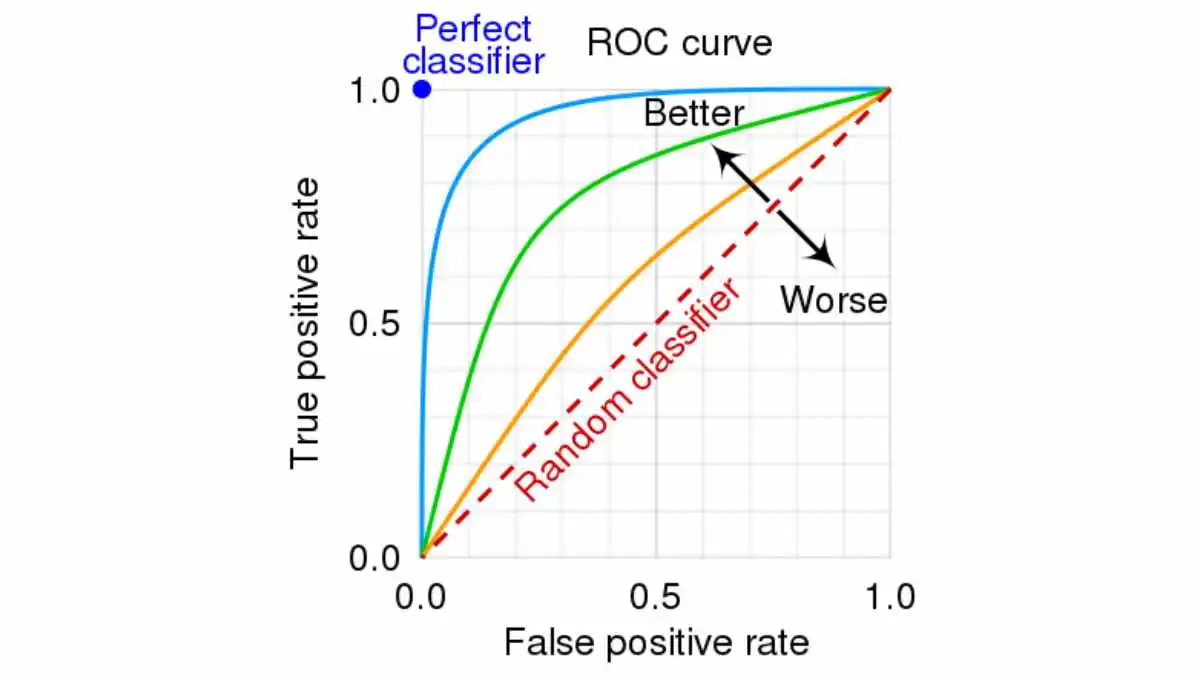



Area under the ROC curve се движи од 0 до 1.

AUC = 1.0 → совршено ги рангира позитивните edges над негативните.

AUC ≈ 0.5 → не ги разликува подобро од случајно рангирање.

AUC под 0.5 → ги рангира полошо од случајното рангирање.

Area under the ROC curve ја мери способноста на моделот да ги рангира позитивните ребра повисоко од негативните.



    y_true.numpy()
    y_score.numpy()

 За да ја направиме ROC кривата прво мора да ги претвораме PyTorch tensors во NumPy arrays, за да можеме да ги проследиме до функцијата од sklearn.   

    На крајот од функцијата ја враќаме вредноста од ROC кривата.

In [35]:
def decode(z, edge):
    src, dst = edge.t()
    return (z[src] * z[dst]).sum(dim=1)

Задачата на оваа функција е да каже колку е веројатно два протеини да имаат врска помеѓу нив. z се embeddings што ги добивме од GCN и
edge се парови на протеини за кои сакаме да провериме дали имаат врска.



>  src, dst = edge.t()

Што значи ова? .t() значи транспонирана матрица односно тоа што било редови станува колони а, тоа што било колони станува редови. Пр.

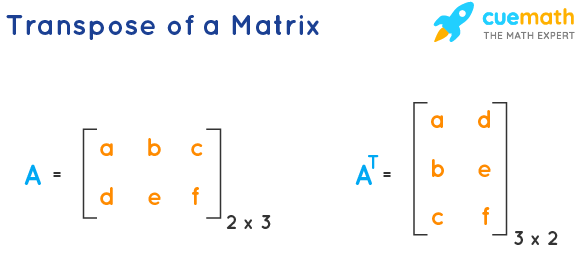


Зошто ни треба транспонирана матрица?
===

Затоа што edge содржи парови на пример прв пар: „[протеинА  протеинБ]“, втор пар „[протеинВ протеинГ]“. Со транспонираната матрица ги разделуваме на две групи изворни протеини и дестинациски протеини. Секој пар изворен и дестинациски протеин се поврзани (формираат ребро). Во нашиот пример би било:


> src = [протеинА, протеинВ] и dest = [протеинБ, протеинГ]


Да се потсетиме дека z ги чува embeddings што ги создавме од моделот па, z[src] и z[dest] ги зема embeddings на соодветните протеини. На пример доколку протеинот 10 има конекција со протеинот 20 тогаш ги земаме нивните embeddings и ги споредуваме.





> return (z[src] * z[dst]).sum(dim=1)

Во последната линија од оваа функција правиме точкаст производ и тоа најдобро ќе го објаснам преку следниот пример:

Ако имаме z[10] = [2, 3, 1] и z[20] = [4, 2, 5] тогаш точкастиот производ е:

> 2×4 + 3×2 + 1×5 = 19 (score)

Повисок score значи дека моделот повеќе верува дека двата протеини се поврзани.
Разликата со реалните податоци е само во тоа што z[10] и z[20] се 64-димензионални вектори (поради моделот) а, не 3 димензионални како во овој пример.



Што значи .sum(dim=1)?
===

dim = 1 значи собирај хоризонтално по редови. z[src] i z[dest] не содржат само еден 64-димензионален вектор. Тие содржат многу такви вектори. И за секој пар помножени z[src] * z[dst] се создава нов вектор кој е производ на нив. За да овие нови вектори да ги претвориме во цели броеви, мораме да ги собереме 64-те броеви за секој вектор поединечно. На тој начин ќе добиеме еден вектор со точкастите производи за секое ребро (секои парови вектори).

In [36]:
model_configs = {
    "GCN-2-layers-32": (2, 32),
    "GCN-2-layers-128": (2, 128),

    "GCN-3-layers-32": (3, 32),
    "GCN-3-layers-128": (3, 128),

    "GCN-4-layers-32": (4, 32),
    "GCN-4-layers-128": (4, 128)
}

Овде дефинираме еден речник со име model_configs кој како клучеви ги има имињата на моделите а, како вредности на тие клучеви содржи два параметри: бројот на слоеви во моделот (невронската мрежа) и број на неврони во скриениот слој.

Овој речник го користиме во кодот подолу.

In [37]:
import time

results = {}

learning_rates = [0.01, 0.001]
num_epochs = 50

for model_name, (num_layers, hidden_channels) in model_configs.items():

    for lr in learning_rates:

        experiment_name = f"{model_name}-lr-{lr}"

        print(f"\nTraining: {experiment_name}")


        model = GCN(
            in_channels=58,
            hidden_channels=hidden_channels,
            num_layers=num_layers
        ).to(device)


        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

        best_auc = 0
        history = []

        for epoch in range(1, num_epochs + 1):

            epoch_start = time.time()


            loss, train_time_sec = train(model, optimizer)


            val_auc = evaluate(model)

            epoch_total_sec = time.time() - epoch_start


            history.append({
                "epoch": epoch,
                "train_loss": loss,
                "val_auc": val_auc,
                "train_time_sec": train_time_sec,
                "epoch_total_sec": epoch_total_sec
            })

            # Save the best model
            if val_auc > best_auc:
                best_auc = val_auc

                torch.save(
                    model.state_dict(),
                    f"best_{experiment_name}.pt"
                )

            print(
                f"Epoch {epoch:02d} | "
                f"Train Loss: {loss:.4f} | "
                f"Val AUC: {val_auc:.4f} | "
                f"Train Time: {train_time_sec:.2f}s | "
                f"Epoch Total: {epoch_total_sec:.2f}s"
            )

        # Store results of the current experiment
        results[experiment_name] = {
            "best_val_auc": best_auc,
            "history": history
        }

        print(f"Best Validation AUC: {best_auc:.4f}")


Training: GCN-2-layers-32-lr-0.01
Epoch 01 | Train Loss: 0.4945 | Val AUC: 0.8927 | Train Time: 6.29s | Epoch Total: 7.46s
Epoch 02 | Train Loss: 0.4849 | Val AUC: 0.8962 | Train Time: 5.30s | Epoch Total: 6.45s
Epoch 03 | Train Loss: 0.4826 | Val AUC: 0.8999 | Train Time: 5.50s | Epoch Total: 6.67s
Epoch 04 | Train Loss: 0.4810 | Val AUC: 0.9038 | Train Time: 5.66s | Epoch Total: 6.90s
Epoch 05 | Train Loss: 0.4807 | Val AUC: 0.9039 | Train Time: 5.30s | Epoch Total: 6.40s
Epoch 06 | Train Loss: 0.4812 | Val AUC: 0.9046 | Train Time: 5.31s | Epoch Total: 6.40s
Epoch 07 | Train Loss: 0.4786 | Val AUC: 0.9089 | Train Time: 5.37s | Epoch Total: 6.58s
Epoch 08 | Train Loss: 0.4781 | Val AUC: 0.9089 | Train Time: 5.53s | Epoch Total: 6.63s
Epoch 09 | Train Loss: 0.4766 | Val AUC: 0.9099 | Train Time: 5.32s | Epoch Total: 6.42s
Epoch 10 | Train Loss: 0.4751 | Val AUC: 0.9138 | Train Time: 5.29s | Epoch Total: 6.37s
Epoch 11 | Train Loss: 0.4741 | Val AUC: 0.9126 | Train Time: 5.34s | Epoch

Во претходниот код направивме вкупно 12 експерименти на 6 модели. Моделите беа:




1.   модел со 2 скриени слоеви и 32 неврони во скриениот слој
2.   модел со 2 скриени слоеви и 128 неврони во скриениот слој
3.   модел со 3 скриени слоеви и 32 неврони во скриениот слој
4.   модел со 3 скриени слоеви и 128 неврони во скриениот слој
5.   модел со 4 скриени слоеви и 32 неврони во скриениот слој
6.   модел со 4 скриени слоеви и 128 неврони во скриениот слој

Секој од овие модели при backpropagation ја пресметува грешката и користи optimizer за да направи промени во тежините и моделот да биде поточен. Овој optimizer е конфигуриран на 2 различни начини: со learning rate = [0.01, 0.001]. Затоа на сите 6 модели ние експериментираме и ги користиме и двете learning rate за да видиме која ќе даде подобри резултати.





*Кодот подолу е многу сличен со тој код во фајлот во кој експериментираме со GAT и таму е детално објаснето што се случува. Затоа од овде понатаму кодот ќе биде само прикажан но, не и објаснет.*

In [38]:
for name, result in results.items():
    print(f"{name}: {result['best_val_auc']:.4f}")


import pandas as pd
import zipfile
from google.colab import files

history_rows = []

for experiment_name, result in results.items():
    for epoch_data in result["history"]:
        history_rows.append({
            "experiment": experiment_name,
            **epoch_data
        })

gcn_history = pd.DataFrame(history_rows)
gcn_history.to_csv("gcn_history.csv", index=False)

with zipfile.ZipFile("gcn_best_models.zip", "w", zipfile.ZIP_DEFLATED) as zipf:
    for experiment_name in results:
        model_file = f"best_{experiment_name}.pt"
        zipf.write(model_file)

files.download("gcn_history.csv")
files.download("gcn_best_models.zip")

GCN-2-layers-32-lr-0.01: 0.9264
GCN-2-layers-32-lr-0.001: 0.9225
GCN-2-layers-128-lr-0.01: 0.9227
GCN-2-layers-128-lr-0.001: 0.9317
GCN-3-layers-32-lr-0.01: 0.9268
GCN-3-layers-32-lr-0.001: 0.9241
GCN-3-layers-128-lr-0.01: 0.9273
GCN-3-layers-128-lr-0.001: 0.9349
GCN-4-layers-32-lr-0.01: 0.9292
GCN-4-layers-32-lr-0.001: 0.9238
GCN-4-layers-128-lr-0.01: 0.9247
GCN-4-layers-128-lr-0.001: 0.9365


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
from torch_geometric.loader import LinkNeighborLoader

test_loader = LinkNeighborLoader(
    data=graph,
    num_neighbors=[5, 5],

    edge_label_index=torch.cat([
        test_edges_small.t(),
        test_edges_neg_small.t()
    ], dim=1),

    edge_label=torch.cat([
        torch.ones(test_edges_small.size(0)),
        torch.zeros(test_edges_neg_small.size(0))
    ]),

    batch_size=256,
    shuffle=False
)

In [40]:
gcn_models = {}

for model_name, (num_layers, hidden_channels) in model_configs.items():

    for lr in learning_rates:

        experiment_name = f"{model_name}-lr-{lr}"

        model = GCN(
            in_channels=58,
            hidden_channels=hidden_channels,
            num_layers=num_layers
        ).to(device)


        model.load_state_dict(
            torch.load(
                f"best_{experiment_name}.pt",
                map_location=device,
                weights_only=True
            )
        )

        model.eval()

        gcn_models[experiment_name] = model

        print(f"Loaded: {experiment_name}")

Loaded: GCN-2-layers-32-lr-0.01
Loaded: GCN-2-layers-32-lr-0.001
Loaded: GCN-2-layers-128-lr-0.01
Loaded: GCN-2-layers-128-lr-0.001
Loaded: GCN-3-layers-32-lr-0.01
Loaded: GCN-3-layers-32-lr-0.001
Loaded: GCN-3-layers-128-lr-0.01
Loaded: GCN-3-layers-128-lr-0.001
Loaded: GCN-4-layers-32-lr-0.01
Loaded: GCN-4-layers-32-lr-0.001
Loaded: GCN-4-layers-128-lr-0.01
Loaded: GCN-4-layers-128-lr-0.001


In [41]:
from sklearn.metrics import roc_auc_score
import torch

@torch.no_grad()
def test(model):
    model.eval()

    all_scores = []
    all_labels = []

    for batch in test_loader:
        batch = batch.to(device)

        z = model(batch.x, batch.edge_index)

        edge_label_index = batch.edge_label_index
        edge_label = batch.edge_label.float()

        score = decode(z, edge_label_index.t())

        prob = torch.sigmoid(score)

        all_scores.append(prob.cpu())
        all_labels.append(edge_label.cpu())

    all_scores = torch.cat(all_scores)
    all_labels = torch.cat(all_labels)

    auc = roc_auc_score(
        all_labels.numpy(),
        all_scores.numpy()
    )

    return auc

In [42]:
test_results = {}

for experiment_name, model in gcn_models.items():

    test_auc = test(model)

    test_results[experiment_name] = test_auc

    print(f"{experiment_name}: Test AUC = {test_auc:.4f}")

GCN-2-layers-32-lr-0.01: Test AUC = 0.9243
GCN-2-layers-32-lr-0.001: Test AUC = 0.9194
GCN-2-layers-128-lr-0.01: Test AUC = 0.9213
GCN-2-layers-128-lr-0.001: Test AUC = 0.9314
GCN-3-layers-32-lr-0.01: Test AUC = 0.9257
GCN-3-layers-32-lr-0.001: Test AUC = 0.9206
GCN-3-layers-128-lr-0.01: Test AUC = 0.9258
GCN-3-layers-128-lr-0.001: Test AUC = 0.9342
GCN-4-layers-32-lr-0.01: Test AUC = 0.9263
GCN-4-layers-32-lr-0.001: Test AUC = 0.9228
GCN-4-layers-128-lr-0.01: Test AUC = 0.9231
GCN-4-layers-128-lr-0.001: Test AUC = 0.9339


In [43]:
import pandas as pd
from google.colab import files

final_rows = []

for experiment_name, result in results.items():

    final_rows.append({
        "model": experiment_name,
        "best_val_auc": result["best_val_auc"],
        "test_auc": test_results[experiment_name],
        "epochs": 50
    })

final_metrics = pd.DataFrame(final_rows)

final_metrics.to_csv("gcn_final_metrics.csv", index=False)

files.download("gcn_final_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>